# Show one value per region on slices

This example walks through various ways to overlay brain region values on histology slices

## Data preparation
For all the examples below, an array of acronyms and an array of values corresponding to each acronym must be provided. 

In [1]:
import numpy as np
# prepare array of acronyms
acronyms = np.array(['VPM', 'VPL', 'PO', 'LP', 'CA1', 'DG-mo', 'SSs5', 'VISa5', 'AUDv6a', 'MOp5', 'FRP5'])
# assign data to each acronym
values = np.arange(len(acronyms))

# acronyms and values must have the same number of rows
assert (acronyms.size == values.size)

Different mappings can be used when plotting the images (see [Brain region mappings](../explanation/brain-region-mappings.qmd) for more information on atlas mappings). The acronyms provided must correspond to the specified map

In [2]:
from iblatlas.regions import BrainRegions
br = BrainRegions()

acronyms_beryl = np.unique(br.acronym2acronym(acronyms, mapping='Beryl'))
values_beryl = np.arange(acronyms_beryl.size)

acronyms_cosmos = np.unique(br.acronym2acronym(acronyms, mapping='Cosmos'))
values_cosmos = np.arange(acronyms_cosmos.size)

## Example 1: Coronal slices

In [3]:
from iblatlas.plots import plot_scalar_on_slice
from iblatlas.atlas import AllenAtlas
ba = AllenAtlas()

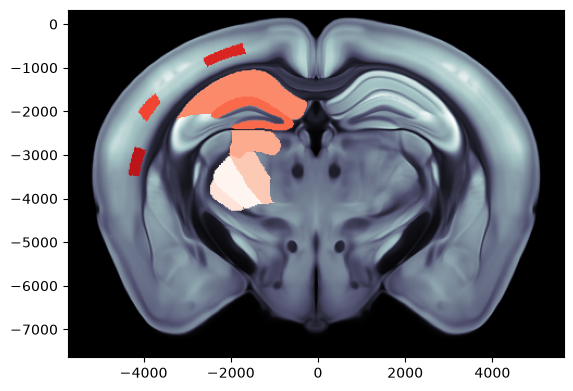

In [4]:
# Plot region values on the left hemisphere of a coronal slice at ap=-2000um overlaid on the dwi Allen image
fig, ax = plot_scalar_on_slice(acronyms, values, coord=-2000, slice='coronal', mapping='Allen', hemisphere='left',
                               background='image', cmap='Reds', brain_atlas=ba)

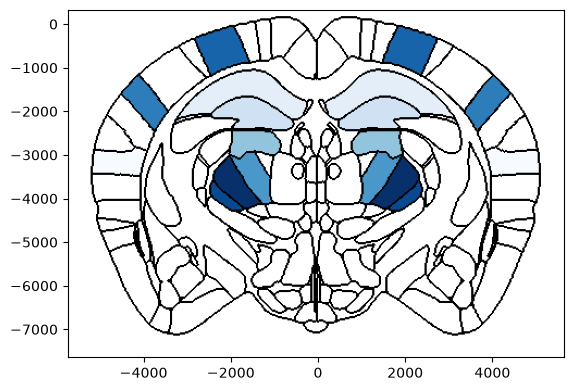

In [5]:
# Plot single column region values on both hemispheres of a coronal slice at ap=-2000um overlaid on brain region boundaries
# using Beryl mapping
# If values only contains one column, the values will be mirrored on each hemisphere
fig, ax = plot_scalar_on_slice(acronyms_beryl, values_beryl, coord=-2000, slice='coronal', mapping='Beryl', 
                               hemisphere='both', background='boundary', cmap='Blues', brain_atlas=ba)

To show different values in each hemisphere, see [Show different values in each hemisphere](show-different-values-in-each-hemisphere.ipynb).

## Example 2: Sagittal slices

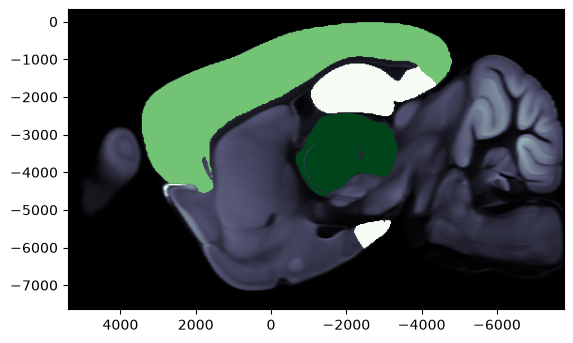

In [6]:
# Plot region values on the left hemisphere of a sagittal slice at ml=-2000um overlaid on the dwi Allen image 
# using cosmos mapping
fig, ax = plot_scalar_on_slice(acronyms_cosmos, values_cosmos, coord=-2000, slice='sagittal', mapping='Cosmos', 
                               hemisphere='left', background='image', cmap='Greens', brain_atlas=ba)

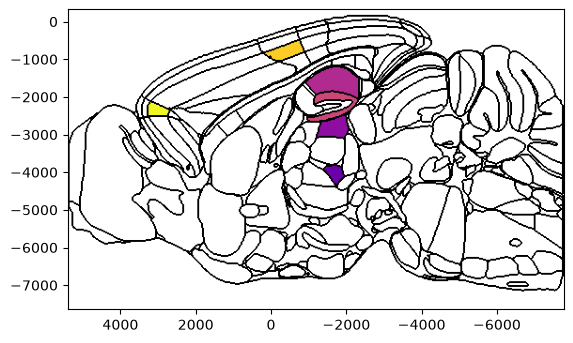

In [7]:
# Plot region values on the left hemisphere of a sagittal slice at ml=-1000um overlaid on brain region boundaries
# Create figure before and pass in axis on which to plot
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
fig, ax = plot_scalar_on_slice(acronyms, values, coord=-1000, slice='sagittal', mapping='Allen', hemisphere='left', 
                               background='boundary', cmap='plasma', brain_atlas=ba, ax=ax)

## Example 3: Horizontal slices

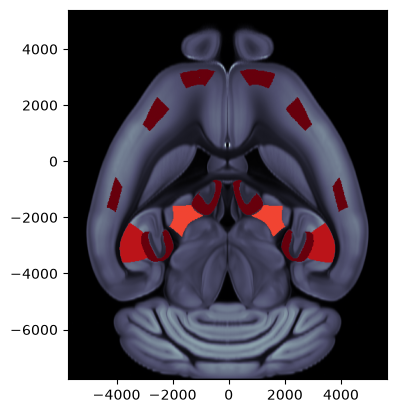

In [8]:
# Plot region values on both hemispheres of a horizontal slice at dv=-2500um overlaid on the dwi Allen image
# Pass in clevels min max values to cap the colormap
fig, ax = plot_scalar_on_slice(acronyms, values, coord=-2500, slice='horizontal', mapping='Allen', hemisphere='both', 
                               background='image', cmap='Reds', brain_atlas=ba, clevels=[0, 5])

## Example 4: Top view

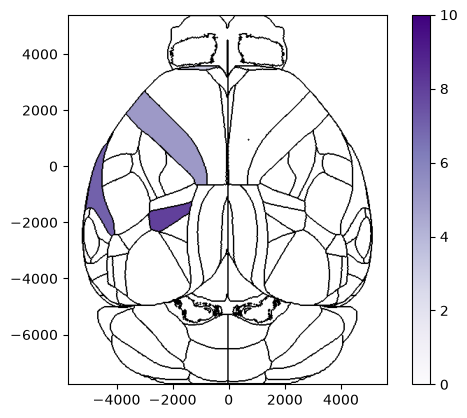

In [9]:
# Plot region values on left hemisphere of a top view overlaid on brain region boundaries using Beryl mapping and show cbar

fig, ax, cbar = plot_scalar_on_slice(acronyms_beryl, values_beryl, slice='top', mapping='Beryl', hemisphere='left', 
                                     background='boundary', cmap='Purples', brain_atlas=ba, show_cbar=True)